# Machine Learning Assignment
## Classification Models – Online Shoppers Purchasing Intention

### 1. Introduction

The aim of this project is to predict whether an online shopping session results in a purchase using machine learning classification techniques.

For this, I have selected the Online Shoppers Purchasing Intention dataset from the UCI Machine Learning Repository. I will implement five classification models, evaluate their performance using different metrics, and compare the results to identify the best-performing model.

### 2. Project Objectives

- Explore and understand the selected dataset.
- Perform data preprocessing and prepare the input features.
- Implement five classification algorithms.
- Evaluate each model using different performance metrics.
- Compare model results and identify the best-performing model.
- Develop a Streamlit application to display model evaluation results.

### 3. Dataset Description

The Online Shoppers Purchasing Intention dataset is obtained from the UCI Machine Learning Repository. It contains visitor browsing information from an e-commerce website, which is used to predict whether a session results in a purchase.

**Dataset Details:**
- Total records: 12,330
- Input features: 17
- Target variable: Revenue
- Classification type: Binary classification
- Target classes: True (Purchase), False (No Purchase)

**Dataset Source:**  
[UCI Machine Learning Repository – Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)

In [1]:
!pip -q install ucimlrepo

In [2]:
# Libraries for data handling and analysis
import pandas as pd
import numpy as np

# Libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library to download the dataset from UCI
from ucimlrepo import fetch_ucirepo

# Display settings
pd.set_option("display.max_columns", None)

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [3]:
# Fetch the Online Shoppers Purchasing Intention dataset
online_shoppers = fetch_ucirepo(id=468)

# Extract input features and target variable
X = online_shoppers.data.features.copy()
y = online_shoppers.data.targets.copy()

# Combine features and target into one DataFrame
df = X.copy()
df["Revenue"] = y.iloc[:, 0]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate records:", df.duplicated().sum())

# Check target variable distribution
print("\nRevenue distribution:")
display(df["Revenue"].value_counts())

# Display target distribution in percentage
print("\nTarget distribution (%):")
display(
    df["Revenue"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Number of rows: 12330
Number of columns: 18

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Number of duplicate records: 125

Revenue distribution:


,count
Revenue,
False,10422
True,1908



Target distribution (%):


,proportion
Revenue,
False,84.53
True,15.47


### 4. Initial Dataset Inspection

The dataset contains 12,330 records and 18 columns,
including 17 input features and one target variable.

There are no missing values in the dataset. However,
125 duplicate rows were identified.

The target variable is imbalanced, with approximately
84.53% of sessions resulting in no purchase and 15.47%
resulting in a purchase.

Therefore, appropriate preprocessing and evaluation
metrics will be considered while building the
classification models.

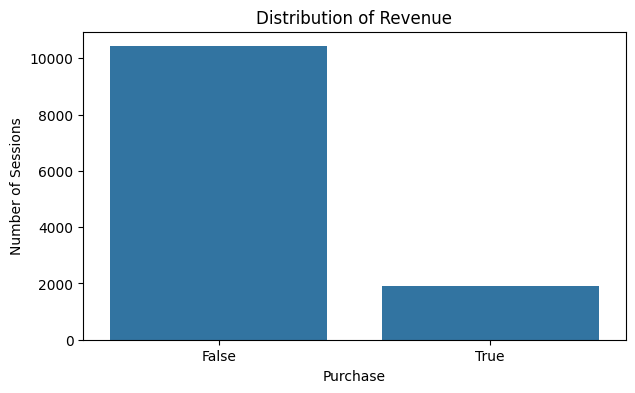

In [5]:
# Visualize the distribution of the target variable

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="Revenue")

plt.title("Distribution of Revenue")
plt.xlabel("Purchase")
plt.ylabel("Number of Sessions")

plt.show()

In [6]:
# Select numerical features for analysis

numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Generate descriptive statistics
display(df[numerical_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


In [7]:
# Identify categorical features

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Display unique values and their frequencies
for column in categorical_features:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts())


Distribution of Month:


,count
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288



Distribution of OperatingSystems:


,count
OperatingSystems,
2,6601
1,2585
3,2555
4,478
8,79
6,19
7,7
5,6



Distribution of Browser:


,count
Browser,
2,7961
1,2462
4,736
5,467
6,174
10,163
8,135
3,105
13,61


... (4 outputs left out)


Distribution of VisitorType:


,count
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85



Distribution of Weekend:


,count
Weekend,
False,9462
True,2868


Revenue,False,True
VisitorType,,
New_Visitor,75.09,24.91
Other,81.18,18.82
Returning_Visitor,86.07,13.93


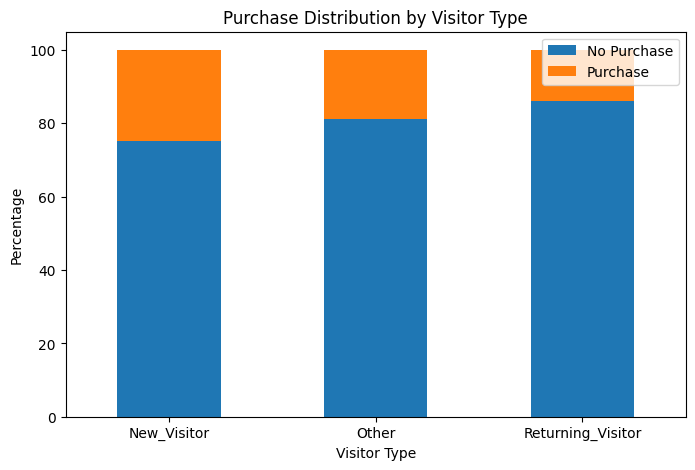

In [8]:
# Analyse purchase behaviour based on visitor type

visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

display(visitor_purchase.round(2))

visitor_purchase.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Purchase Distribution by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Percentage")
plt.legend(["No Purchase", "Purchase"])
plt.xticks(rotation=0)
plt.show()

### 5. Exploratory Data Analysis – Observations

The initial analysis shows that most shopping sessions
do not result in a purchase, indicating an imbalance
in the target variable.

The numerical features show considerable variation,
particularly in product-related browsing duration.
Several features also contain many zero values.

Among the categorical features, returning visitors
make up the majority of sessions. May and November
have the highest number of recorded sessions.

These observations will be considered while selecting
the preprocessing techniques and evaluating the models.

In [9]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().reset_index(drop=True)

# Check the dataset after removing duplicates
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining duplicate records:",
      df_clean.duplicated().sum())

print("\nRevenue distribution after cleaning:")
display(df_clean["Revenue"].value_counts())

print("\nRevenue distribution in percentage:")
display(
    (df_clean["Revenue"].value_counts(normalize=True) * 100).round(2)
)

Original dataset shape: (12330, 18)
Cleaned dataset shape: (12205, 18)

Remaining duplicate records: 0

Revenue distribution after cleaning:


,count
Revenue,
False,10297
True,1908



Revenue distribution in percentage:


,proportion
Revenue,
False,84.37
True,15.63


### 6. Data Cleaning

The dataset initially contained 125 duplicate records.
These records were removed to avoid repeated observations
in the modelling process.

After cleaning, the dataset contains 12,205 records
with no remaining duplicates.

The target distribution remains imbalanced, with
84.37% non-purchase sessions and 15.63% purchase sessions.
This will be considered during model training and evaluation.

In [10]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df_clean.drop(columns=["Revenue"])
y = df_clean["Revenue"].astype(int)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Check target distribution in training and testing data
print("\nTraining target distribution (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

Training data shape: (9764, 17)
Testing data shape: (2441, 17)

Training target distribution (%):


,proportion
Revenue,
0,84.37
1,15.63



Testing target distribution (%):


,proportion
Revenue,
0,84.35
1,15.65


### 7. Train-Test Split

The cleaned dataset was divided into training and
testing sets using an 80:20 ratio.

Stratified sampling was used to maintain a similar
distribution of purchase and non-purchase sessions
in both datasets.

The training set contains 9,764 records, while the
testing set contains 2,441 records.

In [11]:
# Identify numerical features
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Identify categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Verify feature selection
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total selected features:",
      len(numerical_features) + len(categorical_features))

# Check whether all features are covered exactly once
assert set(numerical_features).isdisjoint(categorical_features)
assert set(numerical_features + categorical_features) == set(X_train.columns)

print("\nAll 17 features are correctly categorized.")

Numerical features: 10
Categorical features: 7
Total selected features: 17

All 17 features are correctly categorized.


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define preprocessing for numerical and categorical features
def create_preprocessor():

    preprocessor = ColumnTransformer(
        transformers=[
            ("numerical", StandardScaler(), numerical_features),

            ("categorical", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ), categorical_features)
        ]
    )

    return preprocessor

# Create preprocessing object
preprocessor = create_preprocessor()

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 8. Classification Model Implementation

Five classification algorithms are selected for this
project: Logistic Regression, Decision Tree, K-Nearest
Neighbors, Gaussian Naive Bayes and Support Vector Machine.

Each model uses the same training and testing datasets
with a suitable preprocessing pipeline. The models will
be compared using multiple evaluation metrics to understand
their performance on the selected dataset.

In [14]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [15]:
# Define the five classification models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    )
}

print("Five classification models defined successfully.")

for model_name in models:
    print("-", model_name)

Five classification models defined successfully.
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine


In [16]:
# Create a separate preprocessing pipeline for each model

pipelines = {}

for model_name, model in models.items():

    pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", model)
    ])

print("All five model pipelines created successfully.")

All five model pipelines created successfully.


In [17]:
# Train each model using the training dataset

for model_name, pipeline in pipelines.items():

    print(f"\nTraining {model_name}...")

    pipeline.fit(X_train, y_train)

    print(f"{model_name} training completed.")

print("\nAll five models have been trained successfully!")


Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training KNN...
KNN training completed.

Training Naive Bayes...
Naive Bayes training completed.

Training Support Vector Machine...
Support Vector Machine training completed.

All five models have been trained successfully!


In [18]:
# Verify that all five models have been trained

print("Model training verification:\n")

for model_name, pipeline in pipelines.items():

    is_fitted = hasattr(
        pipeline.named_steps["classifier"],
        "classes_"
    )

    print(f"{model_name}: {'Trained' if is_fitted else 'Not trained'}")

Model training verification:

Logistic Regression: Trained
Decision Tree: Trained
KNN: Trained
Naive Bayes: Trained
Support Vector Machine: Trained


### 9. Model Evaluation

After training the five classification models, their
performance is evaluated using the test dataset.

The evaluation includes Accuracy, AUC, Precision,
Recall, F1 Score and Matthews Correlation Coefficient
(MCC). These metrics help compare the models and
understand how well they identify purchase sessions.

In [19]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

In [20]:
# Store evaluation results and predictions
evaluation_results = []
predictions = {}
prediction_scores = {}

# Evaluate each trained model using the test dataset
for model_name, pipeline in pipelines.items():

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Get scores for calculating AUC
    classifier = pipeline.named_steps["classifier"]

    if hasattr(classifier, "predict_proba"):
        positive_class_index = list(classifier.classes_).index(1)
        y_score = pipeline.predict_proba(X_test)[:, positive_class_index]
    else:
        y_score = pipeline.decision_function(X_test)

    # Store predictions and scores
    predictions[model_name] = y_pred
    prediction_scores[model_name] = y_score

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison DataFrame
results_df = pd.DataFrame(evaluation_results)

# Display results
print("Classification Model Performance Comparison:\n")

display(
    results_df.set_index("Model").round(4)
)

Classification Model Performance Comparison:



,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8460,0.9097,0.5050,0.7958,0.6179,0.5488
Decision Tree,0.8472,0.8449,0.5081,0.7435,0.6036,0.5274
KNN,0.8718,0.8003,0.6533,0.3848,0.4843,0.4357
Naive Bayes,0.2773,0.7502,0.1756,0.9791,0.2978,0.1375
Support Vector Machine,0.8689,0.9095,0.5589,0.7696,0.6476,0.5805


### 10. Model Performance Observations

- Logistic Regression achieved the highest AUC score of 0.9097,
  showing good ability to distinguish between the two classes.

- Decision Tree achieved 84.72% accuracy and provided
  reasonably balanced results.

- KNN achieved the highest accuracy of 87.18%, but its
  recall was relatively low, meaning it missed many
  actual purchase sessions.

- Naive Bayes achieved very high recall but had low
  accuracy and precision, resulting in weaker overall
  performance.

- Support Vector Machine achieved the highest F1 score
  and MCC, providing a better balance between precision
  and recall.

**Overall Best Model: Support Vector Machine (SVM)**

Based on the evaluation results, SVM performed better
overall, particularly in terms of F1 score and MCC.
However, Logistic Regression achieved a slightly higher
AUC score, while KNN achieved the highest accuracy.

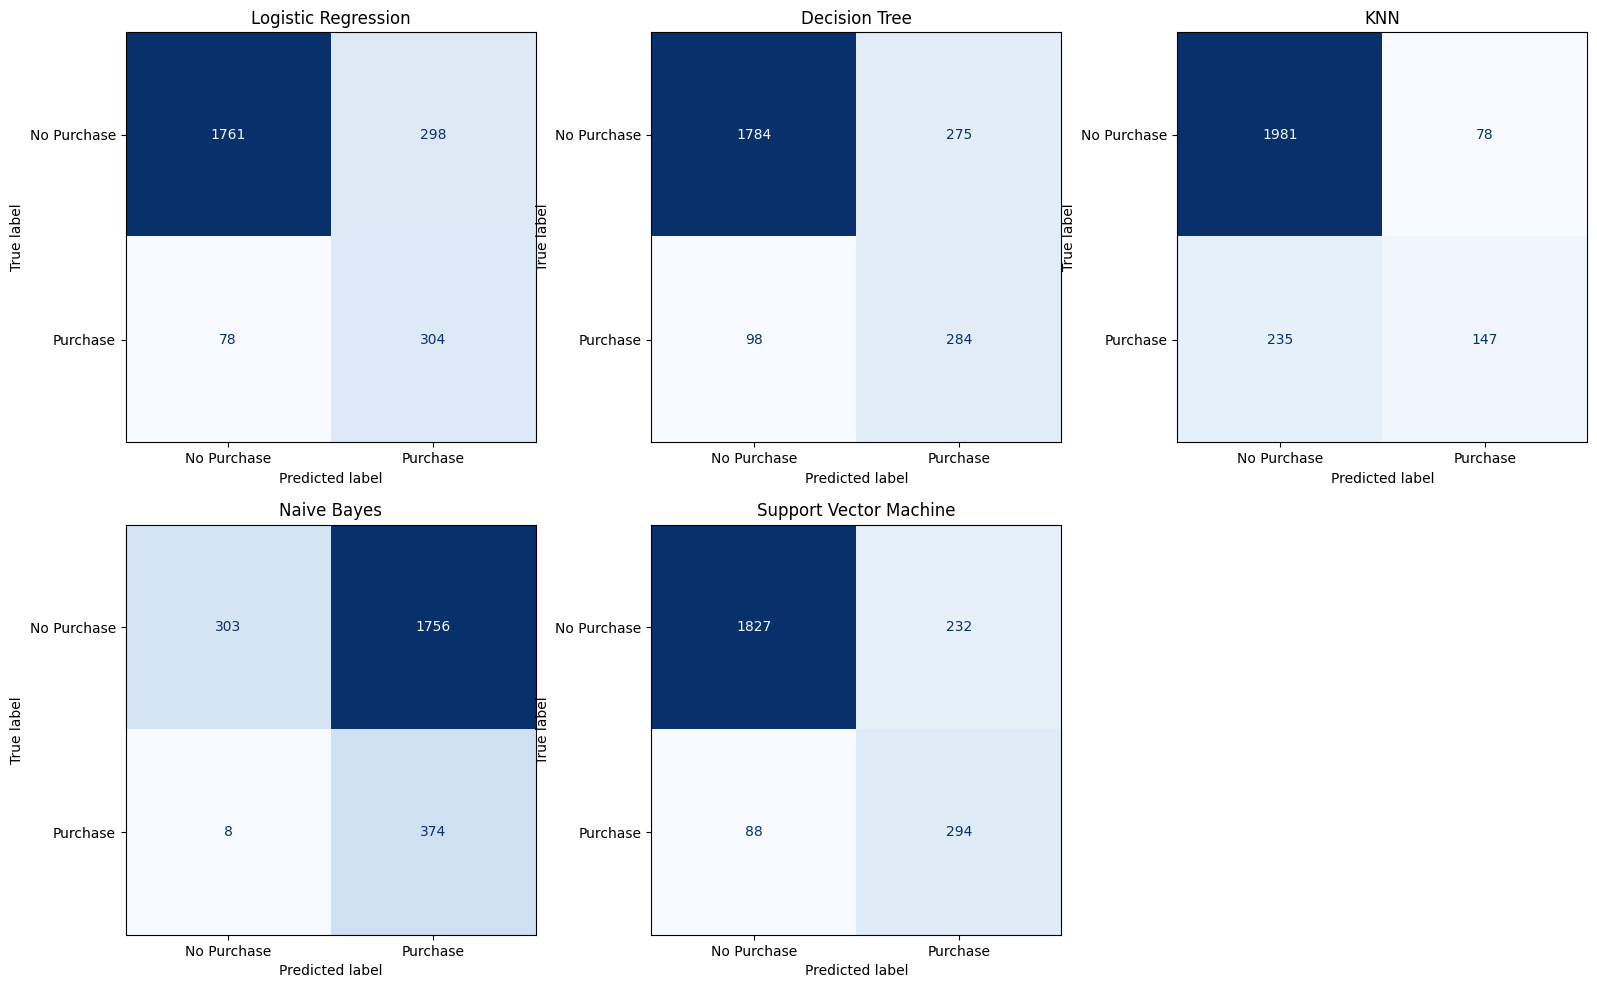

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrices for all five models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Purchase", "Purchase"],
        cmap="Blues",
        ax=axes[i],
        colorbar=False
    )

    axes[i].set_title(model_name)

# Remove the unused sixth plot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [22]:
# Display detailed classification reports

for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(f"Classification Report: {model_name}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Purchase", "Purchase"],
            zero_division=0
        )
    )


Classification Report: Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.96      0.86      0.90      2059
    Purchase       0.50      0.80      0.62       382

    accuracy                           0.85      2441
   macro avg       0.73      0.83      0.76      2441
weighted avg       0.89      0.85      0.86      2441


Classification Report: Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.95      0.87      0.91      2059
    Purchase       0.51      0.74      0.60       382

    accuracy                           0.85      2441
   macro avg       0.73      0.80      0.75      2441
weighted avg       0.88      0.85      0.86      2441


Classification Report: KNN
              precision    recall  f1-score   support

 No Purchase       0.89      0.96      0.93      2059
    Purchase       0.65      0.38      0.48       382

    accuracy                           0.87      2441
   macro avg      

In [23]:
# Compare actual and predicted class distributions

print("Actual test data distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

for model_name, y_pred in predictions.items():

    print(f"\nPredicted distribution – {model_name}")

    distribution = (
        pd.Series(y_pred)
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
        .mul(100)
        .round(2)
    )

    distribution.index = ["No Purchase", "Purchase"]

    display(distribution)

Actual test data distribution:


,proportion
Revenue,
0,84.35
1,15.65



Predicted distribution – Logistic Regression


,proportion
No Purchase,75.34
Purchase,24.66



Predicted distribution – Decision Tree


,proportion
No Purchase,77.1
Purchase,22.9


... (2 outputs left out)


Predicted distribution – Naive Bayes


,proportion
No Purchase,12.74
Purchase,87.26



Predicted distribution – Support Vector Machine


,proportion
No Purchase,78.45
Purchase,21.55


### 11. Classification Report Analysis

The classification reports show differences in how the
models identify purchase and non-purchase sessions.

Logistic Regression and Decision Tree achieved reasonably
balanced results, with good recall for purchase sessions.

KNN achieved the highest accuracy but had lower recall,
meaning it missed a considerable number of actual purchases.

Naive Bayes achieved very high purchase recall but predicted
too many sessions as purchases, resulting in low precision
and accuracy.

SVM provided the best overall balance between precision
and recall, achieving the highest F1 score and MCC.

Based on the current evaluation results, SVM is selected
as the best-performing model for this dataset.

### 12. Saving Trained Models

After evaluating the classification models, all five trained
pipelines are saved using Joblib.

These saved files include both preprocessing steps and
the trained classifiers. They will be reused in the
Streamlit application for making predictions.

In [24]:
import os
import joblib

# Create a folder to store the trained models
os.makedirs("model", exist_ok=True)

# Define model file names
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Save all five trained pipelines
for model_name, pipeline in pipelines.items():

    file_name = model_files[model_name]
    file_path = os.path.join("model", file_name)

    joblib.dump(pipeline, file_path)

    print(f"{model_name} saved successfully.")

print("\nAll five models saved successfully!")

Logistic Regression saved successfully.
Decision Tree saved successfully.
KNN saved successfully.
Naive Bayes saved successfully.
Support Vector Machine saved successfully.

All five models saved successfully!


In [25]:
# Check whether all model files are saved

saved_models = os.listdir("model")

print("Saved model files:")

for file in saved_models:
    print("-", file)

print("\nTotal saved models:", len(saved_models))

Saved model files:
- decision_tree.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- knn.joblib
- svm.joblib

Total saved models: 5


In [26]:
# Combine test features and target variable
test_data = X_test.copy()

test_data["Revenue"] = y_test

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test data shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Test data shape: (2441, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
11640,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,False,0
6936,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,True,0
7194,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,False,0
11263,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,False,0
4728,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,False,0


In [27]:
# Verify the exported test dataset

loaded_test_data = pd.read_csv("test_data.csv")

print("Loaded test dataset shape:", loaded_test_data.shape)

print("\nMissing values:")
print(loaded_test_data.isnull().sum().sum())

print("\nTarget distribution:")
display(loaded_test_data["Revenue"].value_counts())

Loaded test dataset shape: (2441, 18)

Missing values:
0

Target distribution:


,count
Revenue,
0,2059
1,382


In [28]:
# Save model evaluation results
results_df.to_csv("model_comparison.csv", index=False)

print("Model comparison results saved successfully.")

display(results_df.round(4))

Model comparison results saved successfully.


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8460,0.9097,0.5050,0.7958,0.6179,0.5488
1,Decision Tree,0.8472,0.8449,0.5081,0.7435,0.6036,0.5274
2,KNN,0.8718,0.8003,0.6533,0.3848,0.4843,0.4357
3,Naive Bayes,0.2773,0.7502,0.1756,0.9791,0.2978,0.1375
4,Support Vector Machine,0.8689,0.9095,0.5589,0.7696,0.6476,0.5805


In [29]:
import sklearn
import pandas
import numpy
import joblib

# Check saved model files
print("Saved model files:")

for file in sorted(os.listdir("model")):
    print("-", file)

print("\nTotal models:", len(os.listdir("model")))

# Check library versions
print("\nLibrary versions:")
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)

Saved model files:
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- svm.joblib

Total models: 5

Library versions:
Scikit-learn: 1.6.1
Pandas: 2.2.3
NumPy: 2.4.6
Joblib: 1.6.0


In [30]:
import sys
import scipy
import matplotlib

print("Python version:", sys.version)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
SciPy version: 1.16.3
Matplotlib version: 3.10.0


In [31]:
%%writefile app.py

import os
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# --------------------------------------------------
# 1. Application Configuration
# --------------------------------------------------

st.set_page_config(
    page_title="Online Shopper Purchase Analysis",
    page_icon="🛒",
    layout="wide"
)

st.title("Online Shopper Purchase Analysis")

st.write(
    "This application evaluates five machine learning "
    "classification models using online shopping session data."
)

st.markdown("---")


# --------------------------------------------------
# 2. Define Model and Feature Information
# --------------------------------------------------

MODEL_PATHS = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib"
}

FEATURE_COLUMNS = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]


# --------------------------------------------------
# 3. Load Saved Models
# --------------------------------------------------

@st.cache_resource
def load_models():

    loaded_models = {}

    for model_name, model_path in MODEL_PATHS.items():

        if not os.path.exists(model_path):
            raise FileNotFoundError(
                f"Model file not found: {model_path}"
            )

        loaded_models[model_name] = joblib.load(model_path)

    return loaded_models


try:
    models = load_models()
    st.success("All five trained models loaded successfully.")

except Exception as error:
    st.error(f"Unable to load models: {error}")
    st.stop()


# --------------------------------------------------
# 4. Dataset Upload
# --------------------------------------------------

st.header("1. Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload your test dataset (CSV)",
    type=["csv"]
)

if uploaded_file is not None:

    try:
        data = pd.read_csv(uploaded_file)
        st.info("Using the uploaded test dataset.")

    except Exception as error:
        st.error(f"Unable to read CSV file: {error}")
        st.stop()

else:

    default_file = "test_data.csv"

    if not os.path.exists(default_file):
        st.warning(
            "Please upload a test CSV file to continue."
        )
        st.stop()

    data = pd.read_csv(default_file)

    st.info(
        "Using the sample test dataset included in the repository. "
        "You can upload another CSV to evaluate it."
    )


# --------------------------------------------------
# 5. Validate Dataset
# --------------------------------------------------

required_columns = FEATURE_COLUMNS + ["Revenue"]

missing_columns = [
    column for column in required_columns
    if column not in data.columns
]

if missing_columns:
    st.error(
        f"Missing required columns: {missing_columns}"
    )
    st.stop()

if data.empty:
    st.error("The uploaded dataset is empty.")
    st.stop()

if data[required_columns].isnull().any().any():
    st.error(
        "The dataset contains missing values. "
        "Please provide a cleaned test dataset."
    )
    st.stop()

# Prepare input features
X_test = data[FEATURE_COLUMNS].copy()

# Convert target variable into binary values
if pd.api.types.is_bool_dtype(data["Revenue"]):

    y_test = data["Revenue"].astype(int)

else:

    numeric_target = pd.to_numeric(
        data["Revenue"],
        errors="coerce"
    )

    if numeric_target.notna().all() and set(
        numeric_target.unique()
    ).issubset({0, 1}):

        y_test = numeric_target.astype(int)

    else:

        target_mapping = {
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        }

        y_test = (
            data["Revenue"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map(target_mapping)
        )

if y_test.isnull().any():
    st.error("Revenue must contain only True/False or 1/0 values.")
    st.stop()

y_test = y_test.astype(int)

if not set(y_test.unique()).issubset({0, 1}):
    st.error("Revenue must be a binary target with values 0 and 1.")
    st.stop()


# --------------------------------------------------
# 6. Display Dataset Information
# --------------------------------------------------

st.header("2. Dataset Overview")

col1, col2, col3 = st.columns(3)

col1.metric("Total Sessions", f"{len(data):,}")
col2.metric("Input Features", len(FEATURE_COLUMNS))
col3.metric("Purchase Sessions", int(y_test.sum()))

st.write("Uploaded dataset preview:")
st.dataframe(data.head(), use_container_width=True)


# --------------------------------------------------
# 7. Evaluate All Five Models
# --------------------------------------------------

st.header("3. Model Performance Comparison")

evaluation_results = []
model_predictions = {}

for model_name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate score for AUC
    classifier = model.named_steps["classifier"]

    if hasattr(model, "predict_proba"):

        positive_index = list(
            classifier.classes_
        ).index(1)

        y_score = model.predict_proba(
            X_test
        )[:, positive_index]

    else:

        y_score = model.decision_function(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    if len(np.unique(y_test)) == 2:
        auc = roc_auc_score(y_test, y_score)
    else:
        auc = np.nan

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    model_predictions[model_name] = y_pred


results_df = pd.DataFrame(evaluation_results)

st.dataframe(
    results_df.set_index("Model").style.format("{:.4f}"),
    use_container_width=True
)

# Download comparison results
csv_results = results_df.to_csv(index=False)

st.download_button(
    label="Download Model Comparison CSV",
    data=csv_results,
    file_name="model_comparison.csv",
    mime="text/csv"
)


# --------------------------------------------------
# 8. Select a Model
# --------------------------------------------------

st.header("4. Individual Model Evaluation")

selected_model = st.selectbox(
    "Select a classification model",
    list(models.keys()),
    index=list(models.keys()).index("Support Vector Machine")
)

selected_results = results_df[
    results_df["Model"] == selected_model
].iloc[0]

st.subheader(f"{selected_model} – Evaluation Metrics")

metric_columns = st.columns(3)

metric_columns[0].metric(
    "Accuracy",
    f"{selected_results['Accuracy']:.2%}"
)

metric_columns[1].metric(
    "AUC Score",
    f"{selected_results['AUC']:.4f}"
)

metric_columns[2].metric(
    "Precision",
    f"{selected_results['Precision']:.4f}"
)

metric_columns[0].metric(
    "Recall",
    f"{selected_results['Recall']:.4f}"
)

metric_columns[1].metric(
    "F1 Score",
    f"{selected_results['F1 Score']:.4f}"
)

metric_columns[2].metric(
    "MCC",
    f"{selected_results['MCC']:.4f}"
)


# --------------------------------------------------
# 9. Confusion Matrix
# --------------------------------------------------

st.header("5. Confusion Matrix and Classification Report")

selected_predictions = model_predictions[selected_model]

col1, col2 = st.columns(2)

with col1:

    st.subheader("Confusion Matrix")

    cm = confusion_matrix(
        y_test,
        selected_predictions,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(5, 4))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Purchase", "Purchase"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    st.pyplot(fig)
    plt.close(fig)


with col2:

    st.subheader("Classification Report")

    report = classification_report(
        y_test,
        selected_predictions,
        labels=[0, 1],
        target_names=["No Purchase", "Purchase"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    st.dataframe(
        report_df.round(4),
        use_container_width=True
    )


# --------------------------------------------------
# 10. Actual and Predicted Distribution
# --------------------------------------------------

st.header("6. Actual vs Predicted Distribution")

distribution_df = pd.DataFrame({
    "Actual": y_test.value_counts(normalize=True),
    "Predicted": pd.Series(
        selected_predictions
    ).value_counts(normalize=True)
}).reindex([0, 1]).fillna(0)

distribution_df.index = [
    "No Purchase",
    "Purchase"
]

st.dataframe(
    (distribution_df * 100).round(2),
    use_container_width=True
)

st.caption(
    "All evaluation results are calculated using the "
    "uploaded test data and previously trained models. "
    "No model retraining is performed in this application."
)

st.markdown("---")

st.write("Machine Learning Assignment – Classification Models")

Writing app.py


In [32]:
import py_compile

py_compile.compile("app.py", doraise=True)

print("Streamlit application syntax verified successfully.")

Streamlit application syntax verified successfully.


In [33]:
import zipfile
import os

# Create a ZIP containing the saved models and test data
with zipfile.ZipFile(
    "deployment_artifacts.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files_list in os.walk("model"):
        for file in files_list:
            file_path = os.path.join(root, file)
            zip_file.write(file_path, file_path)

    zip_file.write("test_data.csv", "test_data.csv")
    zip_file.write("model_comparison.csv", "model_comparison.csv")

print("Deployment artifacts packaged successfully.")

Deployment artifacts packaged successfully.


In [34]:
from google.colab import files

files.download("app.py")
files.download("deployment_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>